<a href="https://colab.research.google.com/github/ccaauu/analise-viagens-governo-2025/blob/main/analise_viagens_portal_transparencia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de viagens a serviço do governo federal em 2025

**Fonte dos dados:** Portal da Transparência, arquivo `2025_Viagem.csv` (uma linha por viagem).

**Objetivo:** entender quanto, onde e quando o governo federal gastou com viagens a serviço em 2025.

**Perguntas que o projeto responde:**
1. Quanto foi gasto no total?
2. Quais órgãos mais gastaram?
3. Quais são os destinos mais visitados?
4. Qual é o gasto médio por viagem e quais viagens fogem do normal?
5. Como o gasto varia ao longo do ano?

**Ferramentas:** Python, pandas e Google Colab.

## 1. Preparação
Conectar ao Google Drive e carregar os dados.

In [1]:
# Conecta o Colab ao Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

# sep=";" -> colunas separadas por ponto e vírgula
# encoding="latin1" -> acentos corretos
# decimal="," -> valores como 2544,74 são lidos como número
df = pd.read_csv(
    "/content/drive/MyDrive/dados-viagem/2025_Viagem.csv",
    sep=";",
    encoding="latin1",
    decimal=","
)

## 2. Conhecendo os dados
Antes de qualquer análise, vejo o tamanho da tabela, os tipos de cada coluna e os valores vazios.

In [3]:
# Quantas linhas (viagens) e colunas
df.shape

(811504, 22)

In [4]:
# Nome, tipo e quantidade de valores preenchidos de cada coluna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811504 entries, 0 to 811503
Data columns (total 22 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   Identificador do processo de viagem  811504 non-null  int64  
 1   Número da Proposta (PCDP)            811504 non-null  object 
 2   Situação                             811504 non-null  object 
 3   Viagem Urgente                       811504 non-null  object 
 4   Justificativa Urgência Viagem        811178 non-null  object 
 5   Código do órgão superior             811504 non-null  int64  
 6   Nome do órgão superior               811504 non-null  object 
 7   Código órgão solicitante             811504 non-null  int64  
 8   Nome órgão solicitante               811504 non-null  object 
 9   CPF viajante                         803483 non-null  object 
 10  Nome                                 811504 non-null  object 
 11  Cargo        

In [5]:
# Quantidade de valores vazios por coluna
df.isna().sum()

,0
Identificador do processo de viagem,0
Número da Proposta (PCDP),0
Situação,0
Viagem Urgente,0
Justificativa Urgência Viagem,326
Código do órgão superior,0
Nome do órgão superior,0
Código órgão solicitante,0
Nome órgão solicitante,0
CPF viajante,8021


In [6]:
# Quantas viagens há em cada situação
df["Situação"].value_counts()

,count
Situação,
Realizada,802758
Não realizada,8746


**O que vimos:**
- A tabela tem **811.504 viagens** e **22 colunas**, todas de 2025.
- A coluna `Cargo` tem cerca de 305 mil valores vazios.
- Das viagens, **802.758 foram realizadas** e **8.746 não foram realizadas** (cerca de 1,1%).

## 3. Preparando os dados

### Decisões de método
- A análise usa **somente as viagens realizadas**, porque o objetivo é medir quanto custou viajar.
- O gasto é medido pelo **gasto líquido**: diárias + passagens + outros gastos, menos a devolução.
- As colunas novas são criadas **antes** do filtro, para que a tabela filtrada já as contenha.

In [7]:
# Gasto de cada viagem: diárias + passagens + outros gastos
df["gasto_bruto"] = df["Valor diárias"] + df["Valor passagens"] + df["Valor outros gastos"]

# Gasto líquido: desconta o dinheiro devolvido
df["gasto_liquido"] = df["gasto_bruto"] - df["Valor devolução"]

In [8]:
# Converte a data (texto) em data de verdade e extrai o mês
df["data_inicio"] = pd.to_datetime(df["Período - Data de início"], format="%d/%m/%Y")
df["mes"] = df["data_inicio"].dt.month

In [9]:
# Conferência: todas as viagens começam em 2025?
df["data_inicio"].dt.year.value_counts()

,count
data_inicio,
2025,811504


In [10]:
# Filtro: somente viagens realizadas
realizadas = df[df["Situação"] == "Realizada"]

## 4. Perguntas e respostas

### Pergunta 1: quanto foi gasto no total?

In [11]:
# Total gasto nas viagens realizadas (gasto bruto e gasto líquido)
realizadas[["gasto_bruto", "gasto_liquido"]].sum()

,0
gasto_bruto,2.490995e+09
gasto_liquido,2.482039e+09


**Resultado:** as viagens realizadas somam cerca de **2,49 bilhões de reais** em gasto bruto. Descontando as devoluções, o gasto líquido fica em cerca de **2,48 bilhões de reais**.

### Pergunta 2: quais órgãos mais gastaram?

In [12]:
# Os 10 órgãos superiores com maior gasto líquido (valores em milhões de reais)
(
    realizadas.groupby("Nome do órgão superior")["gasto_liquido"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    / 1_000_000
).round(1)

,gasto_liquido
Nome do órgão superior,
Ministério da Justiça e Segurança Pública,818.8
Ministério da Defesa,343.7
Ministério da Educação,321.9
Ministério do Meio Ambiente e Mudança do Clima,132.1
Ministério da Saúde,84.0
Ministério da Previdência Social,78.2
Ministério da Fazenda,71.0
Ministério do Desenvolvimento Agrário e Agricultura Familiar,62.7
Ministério dos Povos Indígenas,57.9


**Resultado:** o Ministério da Justiça e Segurança Pública lidera, com cerca de **819 milhões de reais**, aproximadamente um terço do gasto total. Em seguida vêm o Ministério da Defesa (cerca de 344 milhões) e o Ministério da Educação (cerca de 322 milhões).

**Limitação:** o 10º lugar é "Sem informação", um registro sem órgão identificado.

#### Pergunta 2b: dentro do Ministério da Justiça, quem mais gasta?

In [13]:
# Filtra o Ministério da Justiça e agrupa pelo órgão que solicitou a viagem
justica = realizadas[realizadas["Nome do órgão superior"] == "Ministério da Justiça e Segurança Pública"]

(
    justica.groupby("Nome órgão solicitante")["gasto_liquido"]
    .sum()
    .sort_values(ascending=False)
    / 1_000_000
).round(1)

,gasto_liquido
Nome órgão solicitante,
Ministério da Justiça e Segurança Pública - Unidades com vínculo direto,440.8
Polícia Federal,254.4
Polícia Rodoviária Federal,121.5
Conselho Administrativo de Defesa Econômica,2.3


**Resultado:** mais da metade do gasto vem das unidades do próprio ministério (cerca de 441 milhões de reais), seguidas pela Polícia Federal (cerca de 254 milhões, 31%) e pela Polícia Rodoviária Federal (cerca de 121 milhões, 15%).

### Pergunta 3: quais são os destinos mais visitados?

In [14]:
# Os 10 destinos com mais viagens, sem os registros em sigilo
(
    realizadas[realizadas["Destinos"] != "Informações protegidas por sigilo"]["Destinos"]
    .value_counts()
    .head(10)
)

,count
Destinos,
Brasília/DF,64763
São Paulo/SP,26221
Rio de Janeiro/RJ,25173
São José dos Campos/SP,12793
Belo Horizonte/MG,10049
Belém/PA,8801
Recife/PE,8683
Manaus/AM,8652
Fortaleza/CE,8208


**Resultado:** Brasília lidera, com **64.763 viagens**, seguida por São Paulo (26.221) e Rio de Janeiro (25.173). São José dos Campos aparece em 4º lugar.

**Limitações:**
- Cerca de 14% das viagens têm destino em sigilo, e foram retiradas do ranking.
- Viagens com mais de um destino têm todos os destinos escritos na mesma célula. Cada combinação conta como um valor único, então o ranking mostra os destinos registrados como únicos.

### Pergunta 4: qual é o gasto médio por viagem?

In [15]:
# Resumo estatístico do gasto líquido por viagem
realizadas["gasto_liquido"].describe()

,gasto_liquido
count,802758.000000
mean,3091.889891
std,7362.953386
min,-167.500000
25%,463.180000
50%,1368.940000
75%,3615.692500
max,260105.520000


**Resultado:** o gasto líquido médio por viagem é de cerca de **3,1 mil reais**, mas a **mediana é de cerca de 1,4 mil reais**. A média é mais que o dobro da mediana porque poucas viagens muito caras puxam o valor para cima.

#### Pergunta 4b: quais são as viagens mais caras?

In [16]:
# As 5 viagens mais caras (sem mostrar dados pessoais)
(
    realizadas.sort_values("gasto_liquido", ascending=False)
    [["Nome do órgão superior", "Destinos", "gasto_liquido"]]
    .head(5)
)

,Nome do órgão superior,Destinos,gasto_liquido
187148,Ministério da Defesa,Cingapura/Cingapura,260105.52
10531,Ministério de Minas e Energia,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita,...",245852.80
431,Ministério da Justiça e Segurança Pública,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...",216729.36
43175,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,213987.50
1731,Ministério da Justiça e Segurança Pública,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis...",207220.14


**Resultado:** as viagens mais caras custaram entre **207 mil e 260 mil reais**. Duas têm destino internacional (Cingapura, e Abu Dabi com Riad) e três têm vários destinos na mesma viagem.

#### Pergunta 4c: existem viagens com gasto negativo?

In [17]:
# Quantas viagens têm gasto líquido negativo
realizadas[realizadas["gasto_liquido"] < 0].shape

(8, 26)

**Resultado:** apenas **8 viagens** têm gasto líquido negativo, o que é irrelevante diante de mais de 800 mil viagens.

### Pergunta 5: como o gasto varia ao longo do ano?

In [18]:
# Gasto líquido por mês de início da viagem (milhões de reais)
gasto_mensal = (realizadas.groupby("mes")["gasto_liquido"].sum() / 1_000_000).round(1)
gasto_mensal

,gasto_liquido
mes,
1,287.2
2,117.2
3,201.7
4,166.3
5,205.3
6,200.8
7,149.5
8,220.6
9,249.0


<Axes: title={'center': 'Gasto líquido com viagens por mês em 2025'}, xlabel='Mês', ylabel='Milhões de reais'>

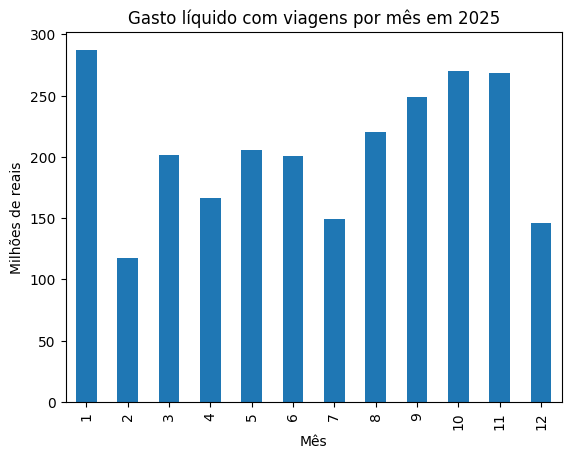

In [19]:
gasto_mensal.plot(
    kind="bar",
    title="Gasto líquido com viagens por mês em 2025",
    xlabel="Mês",
    ylabel="Milhões de reais"
)

**Resultado:** o gasto varia bastante ao longo do ano. **Janeiro** é o mês de maior gasto (cerca de 287 milhões de reais) e **fevereiro** o de menor (cerca de 117 milhões). Outubro e novembro também ficam altos, perto de 270 milhões.

Cada viagem foi contada no mês em que começou.

## 5. Conclusões
- Em 2025, as viagens realizadas custaram cerca de **2,48 bilhões de reais** em gasto líquido.
- O **Ministério da Justiça e Segurança Pública** concentra cerca de um terço do gasto.
- **Brasília** é o destino mais frequente, seguida por São Paulo e Rio de Janeiro.
- A viagem típica custa cerca de 1,4 mil reais (mediana), mas poucas viagens muito caras elevam a média para cerca de 3,1 mil.
- O gasto é irregular ao longo do ano: **janeiro** é o mês mais alto e **fevereiro** o mais baixo.

## 6. Limitações
- A coluna `Cargo` tem cerca de 305 mil valores vazios.
- Cerca de 14% das viagens têm destino em sigilo.
- Viagens com vários destinos contam como um destino único no ranking.
- As 8.746 viagens não realizadas (cerca de 1,1%) ficaram fora da análise.
- O dado mostra o que foi gasto, mas não o motivo de cada padrão.

## 7. Próximos passos
- Cruzar a tabela de viagens com as de passagens, pagamentos e trechos.
- Separar os destinos de viagens com mais de uma cidade, para contar cada cidade individualmente.
- Criar gráficos para os órgãos e para os destinos.